## Hierarchical clustering (Ward linkage)

**Purpose:** test whether the 500 homes form groups under hierarchical clustering, and whether those groups are clearer and more stable than groups formed on shuffled data.

**Input:** the raw data file, `home_features.csv` and `home_segments.csv` (created by `02_Kmeans.ipynb`). None of these files is stored in the repository.

**Requires:** pandas, numpy, matplotlib, scipy, scikit-learn (see `requirements.txt` in the repository root). Random seeds and shuffle counts are listed in this folder's README.

**Summary of findings:** Ward clusters are weakly separated (silhouette 0.03 to 0.05), are not clearly better than clusters formed on shuffled data, are not more stable than shuffled data, and agree with K-means no more than random data do. We find no reliable evidence of meaningful household segments.

### Setup: libraries and data
- Same standardized feature table as K-means (mean kWh per reading for each appliance, 500 homes x 10 appliances).
- K-means labels (k = 3) are loaded for the comparison in section 5.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler

# Raw data (needed for the shuffled baseline)
df = pd.read_csv("../data/raw/smart_home_energy_consumption_large.csv")

# Home-level feature table saved in 02_segmentation
features = pd.read_csv("../data/processed/home_features.csv", index_col="Home ID")
appliance_cols = [c for c in features.columns if c not in ["n_readings", "avg_kwh"]]

# Same standardization as K-means, so the methods are comparable
X = StandardScaler().fit_transform(features[appliance_cols])

# K-means labels (k = 3) for comparison in section 5
segments = pd.read_csv("../data/processed/home_segments.csv", index_col="Home ID")
labels3 = segments["cluster"]

print(X.shape)   # expect (500, 10)

(500, 10)


### 1. Dendrogram and top-merge test
- 1a draws the merge tree for the real data and checks whether it shows a clear break.
- 1b repeats the same check on 100 shuffled datasets to see whether the break in the real tree is larger than random data produce.

### 1a. Dendrogram (Ward linkage)
- Each home starts as its own cluster; the closest clusters are merged step by step.
- Large vertical jumps indicate natural cluster boundaries. Section 1b tests whether the jump seen here is larger than on shuffled data.

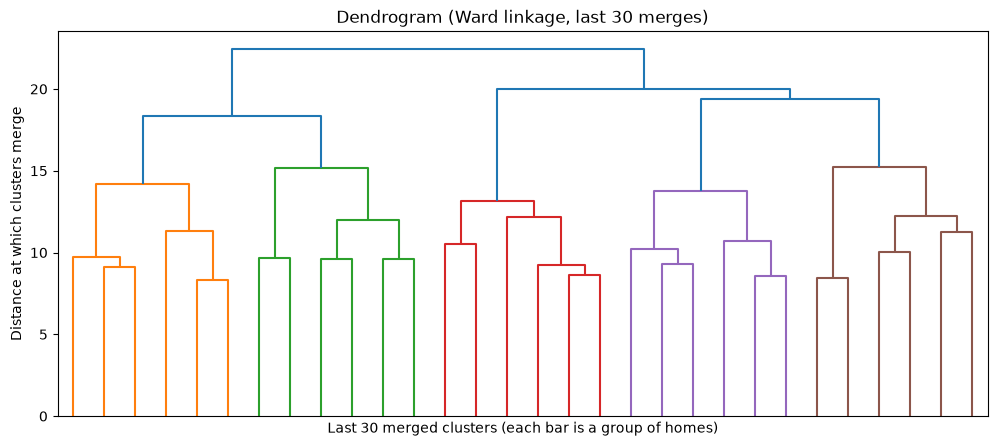

In [10]:
# Build the merge tree on the standardized table X (same input as K-means)
Z = linkage(X, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True)
plt.title("Dendrogram (Ward linkage, last 30 merges)")
plt.xlabel("Last 30 merged clusters (each bar is a group of homes)")
plt.ylabel("Distance at which clusters merge")
plt.show()

**Findings**
- The last merges occur at distances of about 22.4, 20.0, 19.4 and 18.4, decreasing gradually with no large jump.
- No number of clusters is clearly favoured, which is consistent with weak or absent cluster structure.
- Colours in the plot are the library's default threshold colouring and do not indicate meaningful clusters.
- The tree is truncated to the last 30 merges; each bar is a group of homes, not a single home.

### 1b. Shuffled baseline for the top merge
- The ratio of the last merge distance to the second-to-last measures how sharply the tree separates into two groups.
- The ratio is recomputed on 100 shuffled datasets (Home IDs shuffled, feature table rebuilt) to see what trees on random data look like.

In [11]:
# Compare the top merge heights: real vs shuffled data
real_top = Z[-5:, 2]            # last 5 merge distances (largest at the end)
print("Real top merges:", np.round(real_top, 1))

rng = np.random.default_rng(42)
shuffled_gap = []
for _ in range(100):
    ids = rng.permutation(df["Home ID"].values)
    f = (df.assign(shuffled_home=ids)
           .pivot_table(index="shuffled_home", columns="Appliance Type",
                        values="Energy Consumption (kWh)", aggfunc="mean"))
    Zs = linkage(StandardScaler().fit_transform(f), method="ward")
    shuffled_gap.append(Zs[-1, 2] / Zs[-2, 2])   # last merge / second-to-last

real_gap = Z[-1, 2] / Z[-2, 2]
p = (np.sum(np.array(shuffled_gap) >= real_gap) + 1) / (len(shuffled_gap) + 1)
print(f"Real ratio (last / second-to-last merge): {real_gap:.3f}")
print(f"Shuffled mean ratio: {np.mean(shuffled_gap):.3f}, p = {p:.3f}")

Real top merges: [15.2 18.4 19.4 20.  22.4]
Real ratio (last / second-to-last merge): 1.121
Shuffled mean ratio: 1.098, p = 0.347


**Findings**
- Last five merge distances: 15.2, 18.4, 19.4, 20.0, 22.4 (gradual increase, no large jump).
- Ratio of last to second-to-last merge: 1.121 (real) vs 1.098 (shuffled mean); p = 0.347 over 100 shuffles.
- The top of the tree is not distinguishable from trees built on shuffled data.
- This check covers only the split into two clusters; silhouette and stability are assessed separately.

### 2. Silhouette for k = 2 to 8 (Ward linkage)
- Silhouette measures how well each home fits its own cluster compared with the nearest other cluster (1 = well separated, 0 = overlapping; below 0.25 is usually read as little structure).
- The table also shows the size of each cluster, to spot very small clusters.

In [12]:
rows = []
for k in range(2, 9):
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    rows.append({
        "k": k,
        "silhouette": round(silhouette_score(X, labels), 3),
        "cluster_sizes": sorted(pd.Series(labels).value_counts().tolist(), reverse=True)
    })

pd.DataFrame(rows)

,k,silhouette,cluster_sizes
0,2,0.053,"[306, 194]"
1,3,0.038,"[205, 194, 101]"
2,4,0.036,"[194, 121, 101, 84]"
3,5,0.043,"[121, 101, 98, 96, 84]"
4,6,0.034,"[101, 98, 96, 87, 84, 34]"
5,7,0.033,"[101, 96, 87, 84, 57, 41, 34]"
6,8,0.037,"[101, 87, 84, 57, 54, 42, 41, 34]"


**Findings**
- Silhouette ranges from 0.033 to 0.053, below K-means (0.075 to 0.080) and far below 0.25.
- No value of k stands out; the curve is nearly flat.
- Cluster sizes are balanced (for k = 3: 205, 194, 101); no tiny outlier clusters until k = 6, where a cluster of 34 homes appears.
- Lower scores than K-means are expected because Ward linkage does not re-optimise cluster boundaries after merging.

### 3. Shuffled baseline for silhouette (100 shuffles, Ward linkage)
- Home IDs are shuffled, the 500 x 10 table is rebuilt and clustered with Ward linkage for k = 2 to 5.
- The real silhouette is compared with the shuffled scores; the p-value is the share of shuffled runs at least as high as the real score.
- Four values of k are tested, so results are also read after Bonferroni correction (p multiplied by 4).

In [13]:
rng = np.random.default_rng(42)
ks = [2, 3, 4, 5]
n_shuffles = 100

def hier_silhouette(data, k):
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(data)
    return silhouette_score(data, labels)

real_scores = {k: hier_silhouette(X, k) for k in ks}
shuffled_scores = {k: [] for k in ks}

for _ in range(n_shuffles):
    ids = rng.permutation(df["Home ID"].values)
    f = (df.assign(shuffled_home=ids)
           .pivot_table(index="shuffled_home", columns="Appliance Type",
                        values="Energy Consumption (kWh)", aggfunc="mean"))
    Xs = StandardScaler().fit_transform(f)
    for k in ks:
        shuffled_scores[k].append(hier_silhouette(Xs, k))

rows = []
for k in ks:
    arr = np.array(shuffled_scores[k])
    rows.append({
        "k": k,
        "real": round(real_scores[k], 3),
        "shuffled_mean": round(arr.mean(), 3),
        "shuffled_p95": round(np.percentile(arr, 95), 3),
        "p_value": round((np.sum(arr >= real_scores[k]) + 1) / (len(arr) + 1), 3)
    })

pd.DataFrame(rows)

,k,real,shuffled_mean,shuffled_p95,p_value
0,2,0.053,0.049,0.059,0.257
1,3,0.038,0.039,0.046,0.604
2,4,0.036,0.037,0.044,0.564
3,5,0.043,0.035,0.043,0.050


**Findings**
- k = 2: real 0.053 vs shuffled mean 0.049, p = 0.257.
- k = 3: real 0.038 vs shuffled mean 0.039, p = 0.604.
- k = 4: real 0.036 vs shuffled mean 0.037, p = 0.564.
- k = 5: real 0.043 vs shuffled mean 0.035, p = 0.050 (about 0.20 after Bonferroni correction for four values of k).
- For k = 3 and 4 the real data score slightly below the shuffled average.
- K-means shows the same marginal result at k = 5, but both methods use the same data, so this is not independent confirmation.
- Conclusion: no reliable evidence of cluster structure.

### 4. Stability on 80% subsamples vs shuffled data
- Hierarchical clustering has no random start, so stability is tested by removing homes: cluster a random 80% of the homes, then compare with the clustering of all homes on the homes they share (ARI: 1 = identical, 0 = no better than random).
- Each score is the mean of 15 random subsamples (subsample seed 0).
- The same test is repeated on 100 shuffled datasets (seed 42) to see how stable random data are.

In [14]:
def subsample_stability(data, k, n_rounds=15, seed=0):
    """Mean ARI between the full clustering and clusterings of random 80% subsamples."""
    rng_sub = np.random.default_rng(seed)
    full = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(data)
    aris = []
    for _ in range(n_rounds):
        idx = rng_sub.choice(len(data), size=int(0.8 * len(data)), replace=False)
        sub = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(data[idx])
        aris.append(adjusted_rand_score(full[idx], sub))
    return np.mean(aris)

ks = [3, 5]
n_shuffles = 100

# Real data
real_stab = {k: subsample_stability(X, k) for k in ks}

# Shuffled data
rng = np.random.default_rng(42)
shuffled_stab = {k: [] for k in ks}
for _ in range(n_shuffles):
    ids = rng.permutation(df["Home ID"].values)
    f = (df.assign(shuffled_home=ids)
           .pivot_table(index="shuffled_home", columns="Appliance Type",
                        values="Energy Consumption (kWh)", aggfunc="mean"))
    Xs = StandardScaler().fit_transform(f)
    for k in ks:
        shuffled_stab[k].append(subsample_stability(Xs, k))

# Summary
rows = []
for k in ks:
    arr = np.array(shuffled_stab[k])
    rows.append({
        "k": k,
        "real_ARI": round(real_stab[k], 3),
        "shuffled_mean": round(arr.mean(), 3),
        "shuffled_max": round(arr.max(), 3),
        "runs_at_least_as_stable": int(np.sum(arr >= real_stab[k])),
        "p_value": round((np.sum(arr >= real_stab[k]) + 1) / (len(arr) + 1), 3)
    })

pd.DataFrame(rows)

,k,real_ARI,shuffled_mean,shuffled_max,runs_at_least_as_stable,p_value
0,3,0.101,0.101,0.157,45,0.455
1,5,0.165,0.143,0.190,10,0.109


**Findings**
- k = 3: real ARI 0.101 vs shuffled mean 0.101 (max 0.157); 45 of 100 shuffled runs at least as stable; p = 0.455.
- k = 5: real ARI 0.165 vs shuffled mean 0.143 (max 0.190); 10 of 100 at least as stable; p = 0.109 (about 0.22 after correcting for two values of k).
- Absolute ARI is very low: removing 20% of homes largely changes the clustering.
- Stability is not higher than on shuffled data.
- This measure (subsampling) differs from the K-means seed-stability test, so the two ARI values should not be compared directly.
- Conclusion: no evidence of stable cluster structure under Ward linkage.

### 5. Agreement with K-means (k = 3)
- ARI measures how similarly two methods assign homes to clusters (1 = identical, 0 = random agreement).
- The cross-tab shows how the homes of each K-means cluster are spread across Hierarchical clusters.

In [15]:
# Hierarchical labels for k = 3 (same input X as K-means)
hier3 = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X)

# Safety check: both label sets must cover the same 500 homes in the same order
assert len(labels3) == len(hier3) == 500
assert (labels3.index == features.index).all()

# 1. Overall agreement
ari = adjusted_rand_score(labels3.values, hier3)
print("ARI between K-means (k=3) and Hierarchical (k=3):", round(ari, 3))

# 2. How homes are split between the two methods
print(pd.crosstab(labels3.values, hier3,
                  rownames=["kmeans"], colnames=["hierarchical"]))

ARI between K-means (k=3) and Hierarchical (k=3): 0.105
hierarchical   0   1   2
kmeans                  
0             75  31  78
1             93  70  12
2             37  93  11


**Shuffled baseline for agreement**
- K-means and Hierarchical are both run on 100 shuffled datasets (seed 42; K-means `random_state = 0`), and the ARI between them is recorded each time.
- The p-value is the share of shuffled runs with agreement at least as high as the real data.

In [16]:
# Baseline: agreement between K-means and Hierarchical on shuffled data
rng = np.random.default_rng(42)
shuffled_agree = []

for _ in range(100):
    ids = rng.permutation(df["Home ID"].values)
    f = (df.assign(shuffled_home=ids)
           .pivot_table(index="shuffled_home", columns="Appliance Type",
                        values="Energy Consumption (kWh)", aggfunc="mean"))
    Xs = StandardScaler().fit_transform(f)
    km_s = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Xs)
    hc_s = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(Xs)
    shuffled_agree.append(adjusted_rand_score(km_s, hc_s))

arr = np.array(shuffled_agree)
p = (np.sum(arr >= ari) + 1) / (len(arr) + 1)
print(f"Real ARI: {ari:.3f}")
print(f"Shuffled mean: {arr.mean():.3f}, max: {arr.max():.3f}")
print(f"Runs at least as high as real: {int(np.sum(arr >= ari))} of 100, p = {p:.3f}")

Real ARI: 0.105
Shuffled mean: 0.119, max: 0.355
Runs at least as high as real: 53 of 100, p = 0.535


**Findings**
- ARI between K-means and Hierarchical: 0.105.
- Cross-tab: no K-means cluster maps to a single Hierarchical cluster; homes are spread across two or three clusters.
- Shuffled baseline (100 runs): mean ARI 0.119, max 0.355; 53 of 100 runs at least as high as real; p = 0.535.
- Conclusion: the two methods agree no more than they do on random data, so the k = 3 segmentation is method-dependent and should not be presented as distinct household types.

## Conclusion and limitations
- Ward clusters are weakly separated (silhouette 0.033 to 0.053) and are not distinguishable from clusters formed on shuffled data for k = 2, 3 and 4 (p = 0.26 to 0.60). The k = 5 result is marginal (p = 0.05, about 0.20 after correcting for four values of k).
- Stability under 80% subsampling is not higher than on shuffled data (k = 3: p = 0.455; k = 5: p = 0.109), and absolute ARI is very low (0.10 to 0.17).
- The top of the dendrogram shows no sharp break (p = 0.347 against shuffled trees).
- Hierarchical and K-means (k = 3) agree no more than they do on shuffled data (ARI 0.105 vs shuffled mean 0.119, p = 0.535), so the k = 3 grouping is method-dependent and descriptive only. Together with silhouette scores of 0.03 to 0.08 that do not exceed shuffled baselines, we find no reliable evidence of meaningful household segments in this dataset.
- k = 3 is used for comparison with K-means; silhouette is flat across k, so the data favour no number of groups.
- The dataset appears simulated (no seasonality, household size varies within every home), so these findings may not apply to real data.
- The marginal K-means stability result is not replicated here, and K-means and Hierarchical use the same data, so their agreement at k = 5 is not independent confirmation.